<a href="https://colab.research.google.com/github/anisabendada-debug/uk-sme-lending-analysis/blob/main/sme_lending_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
   import pandas as pd

   lending = pd.read_csv("sme_lending.csv")
   rate = pd.read_csv("bank_rate.csv")

   print(lending.head())
   print(rate.head())


        Date  \
0  31 Aug 26   
1  31 Jul 26   
2  30 Jun 26   
3  31 May 26   
4  30 Apr 26   

   Monthly changes of monetary financial institutions' sterling and all foreign currency gross lending to small and medium sized enterprises (in sterling millions) seasonally adjusted \t\t\t\t\t\tRPMZM8B  
0                                               6003                                                                                                                                                         
1                                               6413                                                                                                                                                         
2                                               6022                                                                                                                                                         
3                                               5791                           

In [29]:
lending.columns = ["date", "sme_gross_lending"]

rate.columns = ["date", "bank_rate"]


In [30]:
print(lending.head())
print(rate.head())

        date  sme_gross_lending
0  31 Aug 26               6003
1  31 Jul 26               6413
2  30 Jun 26               6022
3  31 May 26               5791
4  30 Apr 26               6385
        date  bank_rate
0  30 Sep 26       3.75
1  31 Aug 26       3.75
2  31 Jul 26       3.75
3  30 Jun 26       3.75
4  31 May 26       3.75


In [31]:
lending["date"] = pd.to_datetime(lending["date"], dayfirst=True)
rate["date"] = pd.to_datetime(rate["date"], dayfirst=True)
lending["month"] =lending["date"].dt.to_period("M")

/tmp/ipykernel_2032/488811363.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  lending["date"] = pd.to_datetime(lending["date"], dayfirst=True)
/tmp/ipykernel_2032/488811363.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  rate["date"] = pd.to_datetime(rate["date"], dayfirst=True)


In [32]:
print(lending["date"].head())
print(rate["date"].head())


0   2026-08-31
1   2026-07-31
2   2026-06-30
3   2026-05-31
4   2026-04-30
Name: date, dtype: datetime64[ns]
0   2026-09-30
1   2026-08-31
2   2026-07-31
3   2026-06-30
4   2026-05-31
Name: date, dtype: datetime64[ns]


In [33]:
rate["month"] = rate["date"].dt.to.period("M")

In [34]:
rate["month"] = rate["date"].dt.to_period("M")

In [35]:
rate = rate.set_index("date").sort_index()
rate = rate.resample("MS").last().ffill().reset_index()
rate["month"] = rate["date"].dt.to_period("M")


In [36]:
data = lending[["month", "sme_gross_lending"]].merge(
    rate[["month", "bank_rate"]], on="month")
data = data[data["month"] >= "2015-01"]

print(data.shape)
print(data.isna().sum())
print(data.tail())

(140, 3)
month                0
sme_gross_lending    0
bank_rate            0
dtype: int64
       month  sme_gross_lending  bank_rate
135  2015-05               4728        0.5
136  2015-04               5012        0.5
137  2015-03               4843        0.5
138  2015-02               4694        0.5
139  2015-01               4742        0.5


In [37]:
   print(lending["month"].min(), rate["month"].min())


2015-01 2015-01


In [38]:
   data.to_csv("clean_data.csv", index=False)

In [39]:
insolv = pd.read_csv("insolvencies.csv")
print(insolv.shape)
print(insolv.columns)
print(insolv.head(10))

(320, 57)
Index(['period', 'year', 'month', 'total_ew_sa', 'compliq_ew_sa', 'cvl_ew_sa',
       'admin_ew_sa', 'total_ew_nsa', 'compliq_ew_nsa', 'cvl_ew_nsa',
       'admin_ew_nsa', 'cva_ew_nsa', 'rec_ew_nsa', 'mor_ew_nsa',
       'restplan_ew_nsa', 'tot_rate_ew', 'compliq_rate_ew', 'cvl_rate_ew',
       'admin_rate_ew', 'cva_rate_ew', 'rec_rate_ew', 'adcvl_ew_nsa',
       'adcvl_rate_ew', 'cvl_with_bulk_ew', 'cvl_with_bulk_rate_ew',
       'total_sc_nsa', 'compliq_sc_nsa', 'cvl_sc_nsa', 'admin_sc_nsa',
       'cva_sc_nsa', 'rec_sc_nsa', 'mor_sc_nsa', 'restplan_sc_nsa',
       'tot_rate_sc', 'compliq_rate_sc', 'cvl_rate_sc', 'admin_rate_sc',
       'cva_rate_sc', 'rec_rate_sc', 'adcvl_sc_nsa', 'adcvl_rate_sc',
       'total_ni_nsa', 'compliq_ni_nsa', 'cvl_ni_nsa', 'admin_ni_nsa',
       'cva_ni_nsa', 'rec_ni_nsa', 'mor_ni_nsa', 'restplan_ni_nsa',
       'tot_rate_ni', 'compliq_rate_ni', 'cvl_rate_ni', 'admin_rate_ni',
       'cva_rate_ni', 'rec_rate_ni', 'adcvl_ni_nsa', 'adcvl_rate_ni'

In [40]:
insolv = insolv[["period", "total_ew_sa"]].copy()
insolv.columns = ["month","insolvencies"]
insolv["month"] = pd.to_datetime(insolv["month"]).dt.to_period("M")
insolv["insolvencies"] = pd.to_numeric(insolv["insolvencies"], errors="coerce")
print(insolv.tail())

       month  insolvencies
315  2026-04          2083
316  2026-05          1860
317  2026-06          1850
318  2026-07          1934
319  2026-08          1946


In [41]:
data = data.merge(insolv, on="month", how="left")
print(data.shape)
print(data.isna().sum())
print(data.tail())

(140, 4)
month                0
sme_gross_lending    0
bank_rate            0
insolvencies         0
dtype: int64
       month  sme_gross_lending  bank_rate  insolvencies
135  2015-05               4728        0.5          1209
136  2015-04               5012        0.5          1235
137  2015-03               4843        0.5          1214
138  2015-02               4694        0.5          1301
139  2015-01               4742        0.5          1129


In [42]:
data = data.sort_values("month").reset_index(drop=True)
print(data.head())
data.to_csv("clean_data.csv", index=False)

     month  sme_gross_lending  bank_rate  insolvencies
0  2015-01               4742        0.5          1129
1  2015-02               4694        0.5          1301
2  2015-03               4843        0.5          1214
3  2015-04               5012        0.5          1235
4  2015-05               4728        0.5          1209


In [43]:
data.to_csv("clean_data.csv", index=False)

1. H1: SME gross lending fell after Bank Rate started rising in December 2021.
2. H2: the effect shows up with a delay of 3-12 months rather than immediately.
3. H3: company insolvencies rose as rates rose, as debt costs squeezed weaker firms.


In [44]:
data["period"] = "1. Pre-Covid (Jan 2015-Feb 2020)"
data.loc[data["month"] >= "2020-03", "period"] = "2. Covid (Mar 2020-Nov 2021)"
data.loc[data["month"] >= "2021-12", "period"] = "3. Rising rates (Dec 2021 on)"

print(data["period"].value_counts())

period
1. Pre-Covid (Jan 2015-Feb 2020)    62
3. Rising rates (Dec 2021 on)       57
2. Covid (Mar 2020-Nov 2021)        21
Name: count, dtype: int64


In [45]:
summary = data.groupby("period")[["sme_gross_lending", "bank_rate", "insolvencies"]].mean().round(1)
print(summary)

                                  sme_gross_lending  bank_rate  insolvencies
period                                                                      
1. Pre-Covid (Jan 2015-Feb 2020)             4820.8        0.5        1287.4
2. Covid (Mar 2020-Nov 2021)                 7031.5        0.1        1068.1
3. Rising rates (Dec 2021 on)                5411.2        3.8        1963.7


<Axes: xlabel='month'>

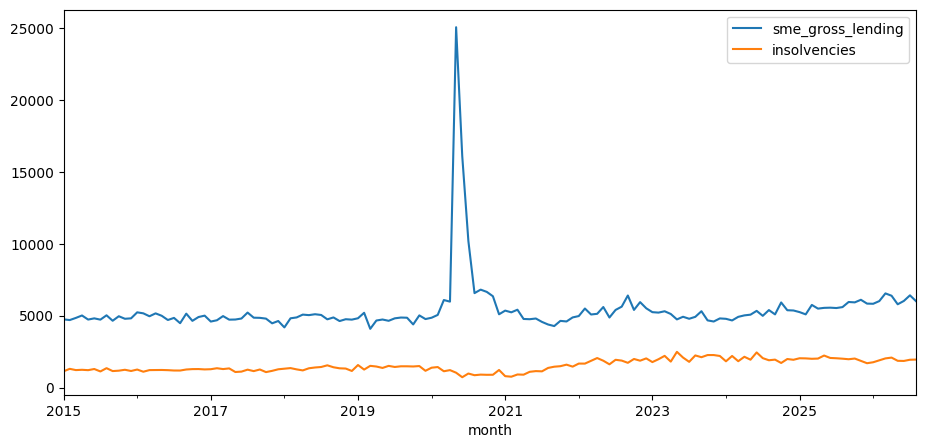

In [46]:
data.plot(x="month", y=["sme_gross_lending", "insolvencies"], figsize=(11, 5))


<Axes: title={'center': 'SME gross lending since mid-2021 (£m)'}, xlabel='Date'>

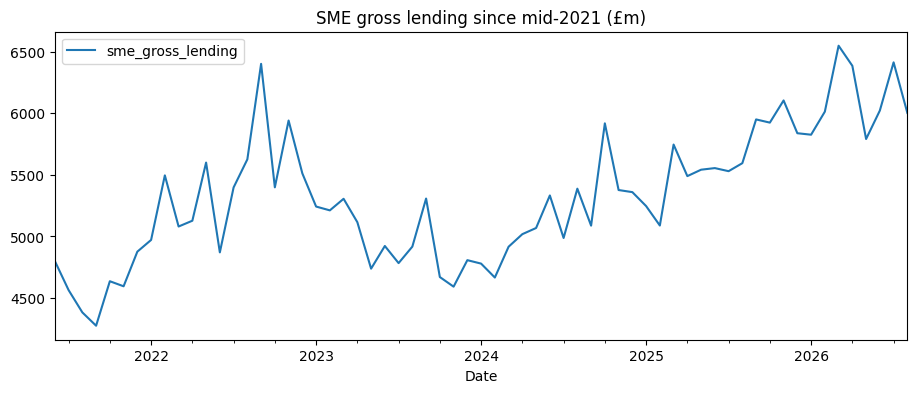

In [47]:
recent = data[data["month"] >= "2021-06"]
recent.plot(x="month", y=["sme_gross_lending"], figsize=(11, 4), title="SME gross lending since mid-2021 (£m)", xlabel="Date")

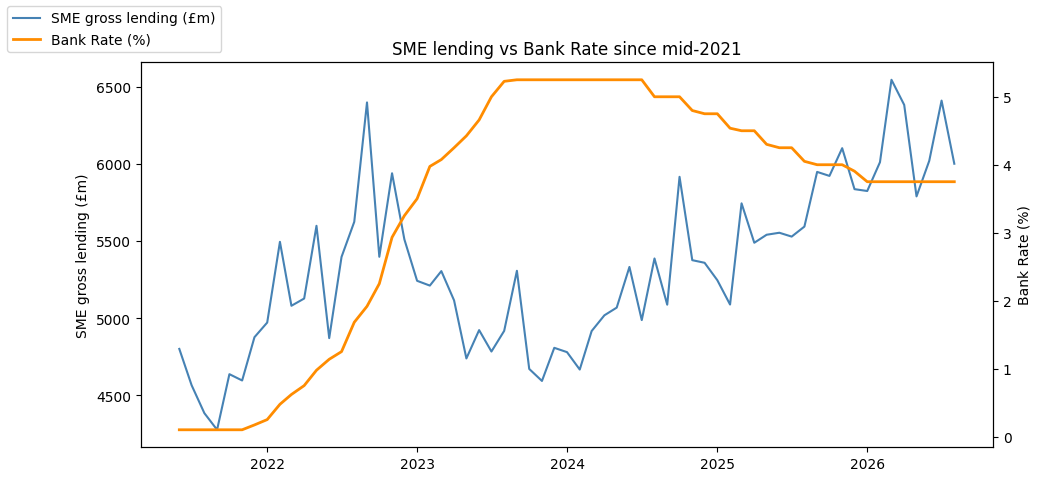

In [48]:
import matplotlib.pyplot as plt

plot = data[data["month"] >= "2021-06"].copy()
plot["date"] = plot["month"].dt.to_timestamp()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(plot["date"], plot["sme_gross_lending"], color="steelblue", label="SME gross lending (£m)")
ax1.set_ylabel("SME gross lending (£m)")

ax2 = ax1.twinx()
ax2.plot(plot["date"], plot["bank_rate"], color="darkorange", linewidth=2, label="Bank Rate (%)")
ax2.set_ylabel("Bank Rate (%)")

ax1.set_title("SME lending vs Bank Rate since mid-2021")
fig.legend(loc="upper left")
plt.show()

In [49]:
for lag in [0, 3, 6, 12]:
    corr = plot["bank_rate"].corr(plot["sme_gross_lending"].shift(-lag))
    print(f"Lag {lag} months: correlation = {corr:.2f}")

Lag 0 months: correlation = 0.18
Lag 3 months: correlation = 0.08
Lag 6 months: correlation = 0.01
Lag 12 months: correlation = 0.24


Simple correlation didn’t capture the effect, because the relationship changed over time. The visual analysis showed lending responded with roughly a 10–12 month delay once rates passed about 3%.


In [50]:
cpi = pd.read_csv("cpi.csv", header=None, names=["period", "cpi"])
cpi = cpi[cpi["period"].str.match(r"^\d{4} [A-Z]{3}$", na=False)].copy()
cpi["month"] = pd.to_datetime(cpi["period"], format ="%Y %b").dt.to_period("M")
cpi["cpi"] = pd.to_numeric(cpi["cpi"])
print(cpi.tail())

       period    cpi    month
661  2026 MAY  142.4  2026-05
662  2026 JUN  142.5  2026-06
663  2026 JUL  142.9  2026-07
664  2026 AUG  143.6  2026-08
665  2026 SEP  144.1  2026-09


In [51]:
data = data.merge (cpi[["month", "cpi"]], on="month", how="left")
base = data["cpi"].iloc[-1]
data["real_lending"] = data["sme_gross_lending"] * base / data ["cpi"]
print(data[["month", "sme_gross_lending", "cpi", "real_lending"]].round(0).tail())
print(data.isna().sum)


       month  sme_gross_lending    cpi  real_lending
135  2026-04               6385  142.0        6452.0
136  2026-05               5791  142.0        5840.0
137  2026-06               6022  142.0        6068.0
138  2026-07               6413  143.0        6444.0
139  2026-08               6003  144.0        6003.0
<bound method DataFrame.sum of      month  sme_gross_lending  bank_rate  insolvencies  period    cpi  \
0    False              False      False         False   False  False   
1    False              False      False         False   False  False   
2    False              False      False         False   False  False   
3    False              False      False         False   False  False   
4    False              False      False         False   False  False   
..     ...                ...        ...           ...     ...    ...   
135  False              False      False         False   False  False   
136  False              False      False         False   False  Fal

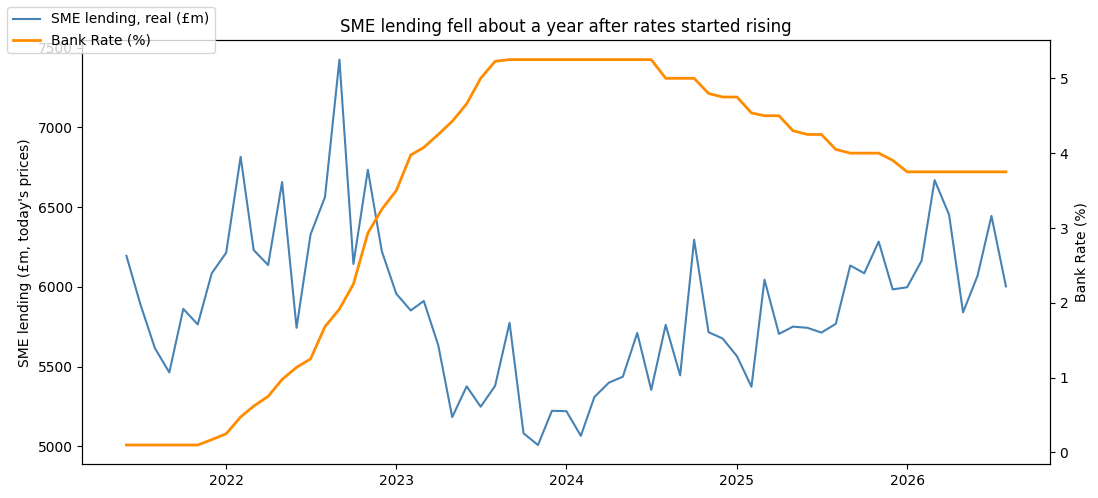

In [52]:
import matplotlib.pyplot as plt

plot = data[data["month"] >= "2021-06"].copy()
plot["date"] = plot["month"].dt.to_timestamp()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(plot["date"], plot["real_lending"], color="steelblue", label="SME lending, real (£m)")   # CHANGED
ax1.set_ylabel("SME lending (£m, today's prices)")   # CHANGED

ax2 = ax1.twinx()
ax2.plot(plot["date"], plot["bank_rate"], color="darkorange", linewidth=2, label="Bank Rate (%)")
ax2.set_ylabel("Bank Rate (%)")

ax1.set_title("SME lending fell about a year after rates started rising")   # CHANGED
fig.legend(loc="upper left")
plt.tight_layout()   # NEW
plt.savefig("chart1_rate_vs_lending.png", dpi=150, bbox_inches="tight")   # NEW
plt.show()

In [53]:
print(data.groupby("period")[["sme_gross_lending", "real_lending"]].mean().round(0))

                                  sme_gross_lending  real_lending
period                                                           
1. Pre-Covid (Jan 2015-Feb 2020)             4821.0        6683.0
2. Covid (Mar 2020-Nov 2021)                 7031.0        9215.0
3. Rising rates (Dec 2021 on)                5411.0        5879.0


Adjusted for inflation, average monthly SME lending during rising rates was about 12% lower than pre-Covid (£5.9bn against £6.7bn in today’s prices). In cash terms it looked 12% higher; inflation masked the real fall.

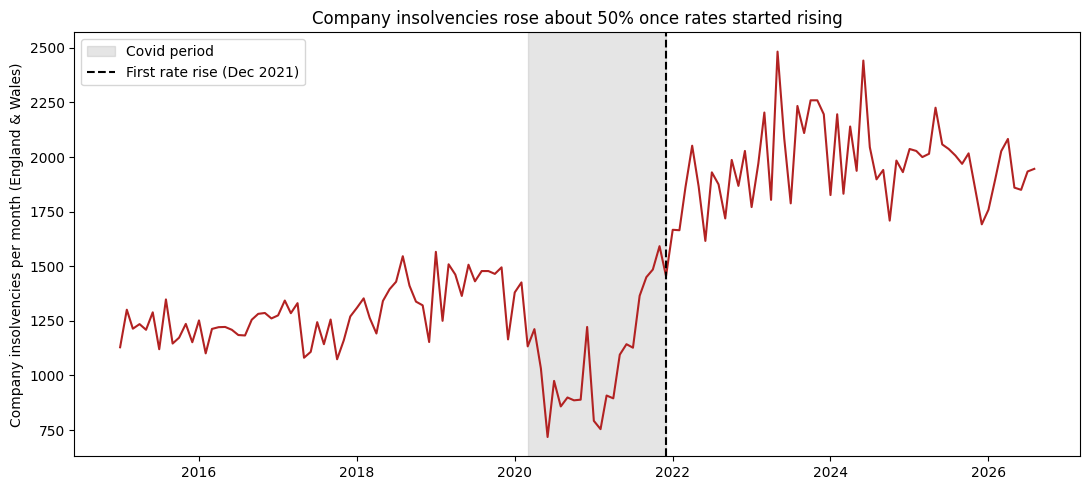

In [54]:
data["date"] = data["month"].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(data["date"], data["insolvencies"], color="firebrick")

ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-11-30"), color="grey", alpha=0.2, label="Covid period")
ax.axvline(pd.Timestamp("2021-12-01"), color="black", linestyle="--", label="First rate rise (Dec 2021)")

ax.set_ylabel("Company insolvencies per month (England & Wales)")
ax.set_title("Company insolvencies rose about 50% once rates started rising")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("chart2_insolvencies.png", dpi=150, bbox_inches="tight")
plt.show()

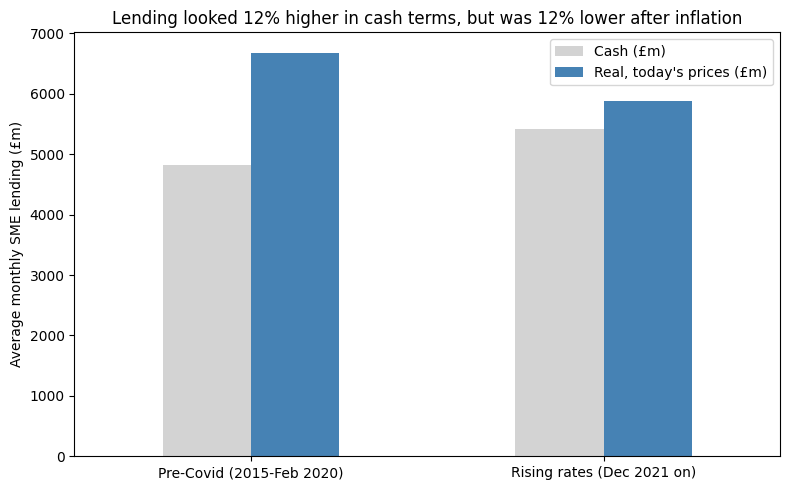

In [55]:
comp = data[data["period"] != "2. Covid (Mar 2020-Nov 2021)"]
summary2 = comp.groupby("period")[["sme_gross_lending", "real_lending"]].mean()

summary2.index = ["Pre-Covid (2015-Feb 2020)", "Rising rates (Dec 2021 on)"]
summary2.columns = ["Cash (£m)", "Real, today's prices (£m)"]

ax = summary2.plot(kind="bar", figsize=(8, 5), rot=0, color=["lightgrey", "steelblue"])
ax.set_ylabel("Average monthly SME lending (£m)")
ax.set_title("Lending looked 12% higher in cash terms, but was 12% lower after inflation")
plt.tight_layout()
plt.savefig("chart3_inflation_flip.png", dpi=150, bbox_inches="tight")
plt.show()